# Manual Network


In [1]:
# Import the necessary libraries.
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
# Import the necessary libraries.
import tensorflow as tf
import glob
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dense, MaxPooling2D, Flatten, Convolution2D, Dropout, BatchNormalization

2025-03-05 18:41:33.649003: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
# Ignoring the warings
import warnings
warnings.filterwarnings("ignore")

In [4]:
dir_name_train_violence = 'datasets/train/violence'
dir_name_train_non_violence = 'datasets/train/non_violence'

In [5]:
def plot_images(item_dir, n=5):
    all_item_dir = os.listdir(item_dir)
    item_files = [os.path.join(item_dir, file) for file in all_item_dir][:n]
    
    plt.figure(figsize=(35, 10))
    for idx, img_path in enumerate(item_files):
        plt.subplot(2, n, idx+1)
        img = plt.imread(img_path)
        plt.imshow(img, cmap='gray')
        plt.axis('off')
    
    plt.tight_layout()

In [6]:
def Images_details_Print_data(data, path):
    print(" ====== Images in: ", path)    
    for k, v in data.items():
        print("%s:\t%s" % (k, v))

def Images_details(path):
    files = [f for f in glob.glob(path + "**/*.*", recursive=True)]
    data = {}
    data['images_count'] = len(files)
    data['min_width'] = 10**100  # No image will be bigger than that
    data['max_width'] = 0
    data['min_height'] = 10**100  # No image will be bigger than that
    data['max_height'] = 0


    for f in files:
        im = Image.open(f)
        width, height = im.size
        data['min_width'] = min(width, data['min_width'])
        data['max_width'] = max(width, data['max_height'])
        data['min_height'] = min(height, data['min_height'])
        data['max_height'] = max(height, data['max_height'])

    Images_details_Print_data(data, path)


Trainned data for  :

 ====== Images in:  datasets/train/violence
images_count:	700
min_width:	162
max_width:	1920
min_height:	240
max_height:	1920



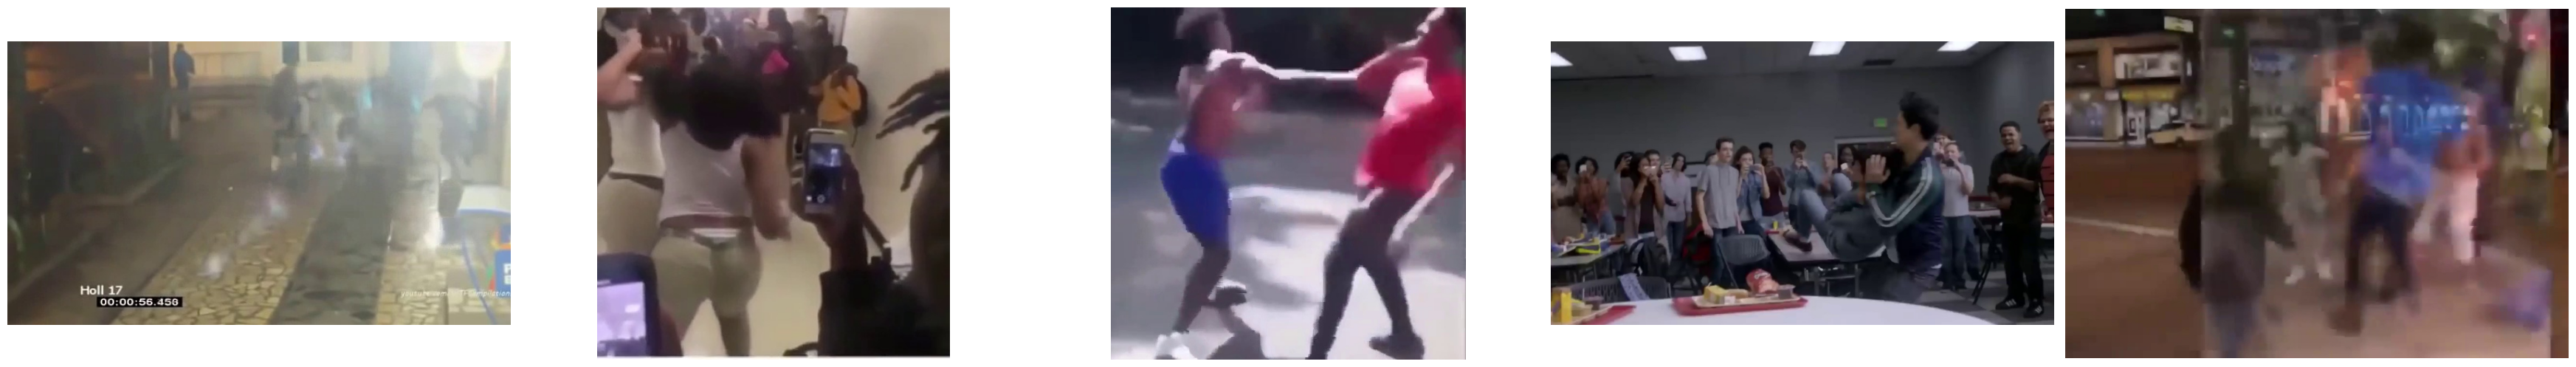

In [7]:
print("")
print("Trainned data for  :")
print("")

Images_details(dir_name_train_violence)
print("")
plot_images(dir_name_train_violence)


Trainned data for  :

 ====== Images in:  datasets/train/non_violence
images_count:	700
min_width:	224
max_width:	1080
min_height:	224
max_height:	1080



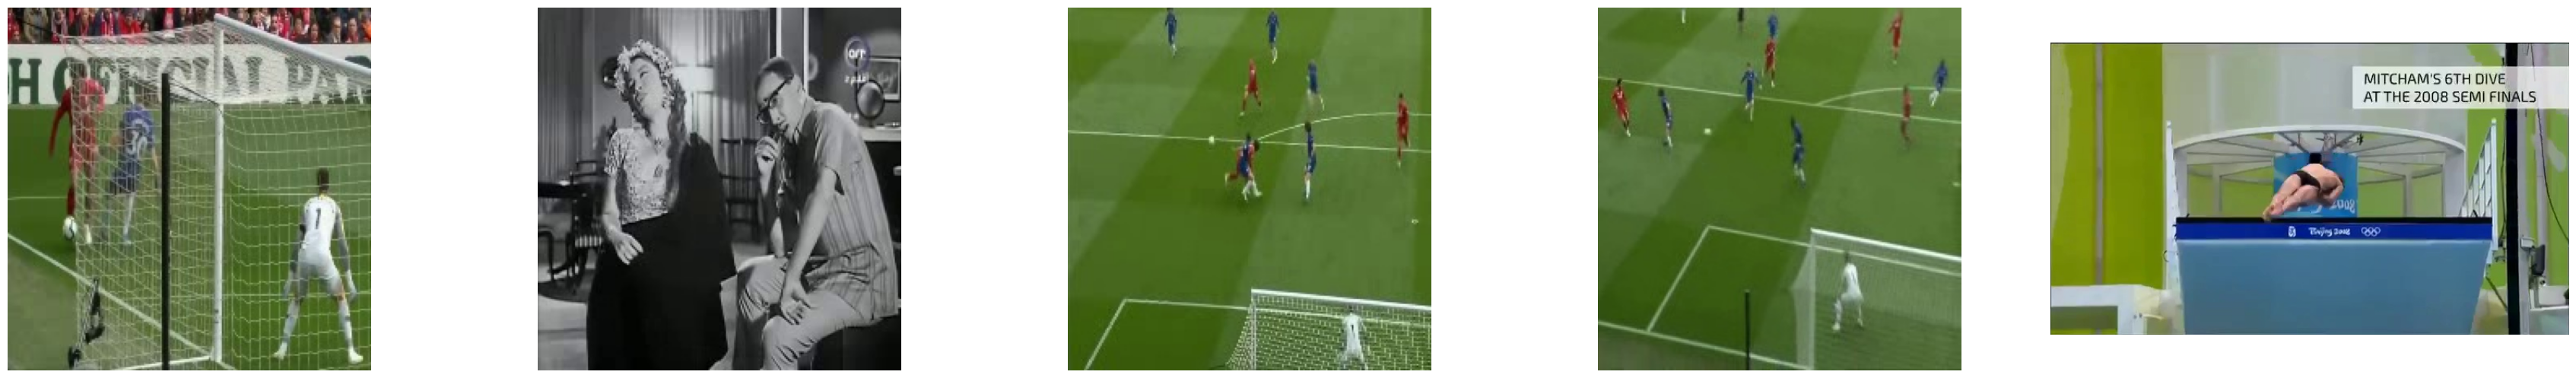

In [8]:
print("")
print("Trainned data for  :")
print("")

Images_details(dir_name_train_non_violence)
print("")
plot_images(dir_name_train_non_violence)

In [9]:
### Data augmentation
train_datagen=ImageDataGenerator(rescale=1./255, shear_range=0.2, zoom_range=0.2, horizontal_flip=True)
test_datagen=ImageDataGenerator(rescale=1./255)

In [10]:
# having train and test images
training_set=train_datagen.flow_from_directory('datasets/train', batch_size=32, class_mode='categorical', target_size=(255,255))
testing_set=test_datagen.flow_from_directory('datasets/test', batch_size=32, class_mode='categorical', target_size=(255,255))

Found 1400 images belonging to 2 classes.
Found 600 images belonging to 2 classes.


In [11]:
## Creating cnn layer

# initialized the model
model=Sequential()  

# Adding first convolution layer
model.add(Convolution2D(32,(3,3),input_shape=(255,255,3), padding='same', activation='relu'))

# Adding first Maxpool layer
model.add(MaxPooling2D(pool_size=(2,2)))

# Adding Flatten layer
model.add(Flatten())

# Adding input layer
model.add(Dense(units=64, activation='relu', ))

# Adding dropout layer
model.add(Dropout(0.4))

# Adding output layer
model.add(Dense(units=2, activation='softmax'))


model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 255, 255, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 127, 127, 32)      0         
 D)                                                              
                                                                 
 flatten (Flatten)           (None, 516128)            0         
                                                                 
 dense (Dense)               (None, 64)                33032256  
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 2)                 130       
                                                        

In [12]:
# Compilin the model

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [13]:
# Fitting the model

history= model.fit(training_set, 
          steps_per_epoch= training_set.samples//32, 
          validation_data=testing_set, 
          validation_steps= testing_set.samples//32, 
          epochs=10)

Epoch 1/10
43/43 [==============================] - 81s 2s/step - loss: 7.6428 - accuracy: 0.6937 - val_loss: 0.4293 - val_accuracy: 0.8160
Epoch 2/10
43/43 [==============================] - 80s 2s/step - loss: 0.3467 - accuracy: 0.8414 - val_loss: 0.2669 - val_accuracy: 0.8906
Epoch 3/10
43/43 [==============================] - 81s 2s/step - loss: 0.2838 - accuracy: 0.8772 - val_loss: 0.2262 - val_accuracy: 0.9149
Epoch 4/10
43/43 [==============================] - 84s 2s/step - loss: 0.2544 - accuracy: 0.8904 - val_loss: 0.1932 - val_accuracy: 0.9201
Epoch 5/10
43/43 [==============================] - 86s 2s/step - loss: 0.2170 - accuracy: 0.9079 - val_loss: 0.1490 - val_accuracy: 0.9566
Epoch 6/10
43/43 [==============================] - 120s 3s/step - loss: 0.2136 - accuracy: 0.9225 - val_loss: 0.1685 - val_accuracy: 0.9340
Epoch 7/10
43/43 [==============================] - 112s 3s/step - loss: 0.1821 - accuracy: 0.9320 - val_loss: 0.2264 - val_accuracy: 0.9149
Epoch 8/10
43/43 [

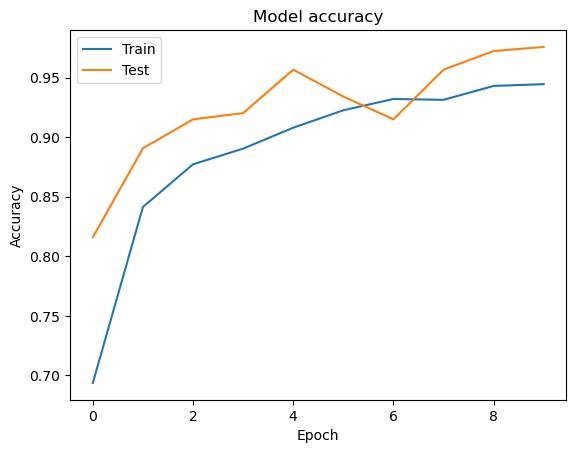

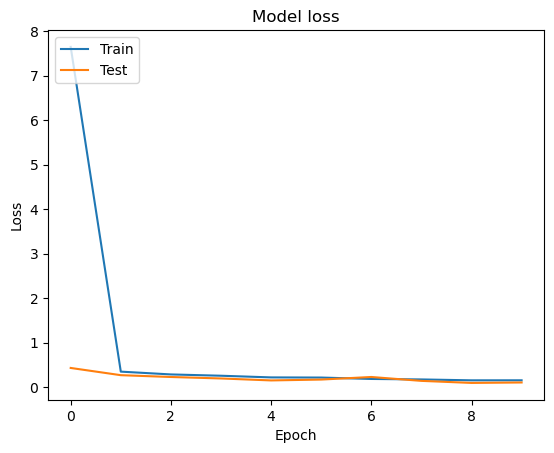

In [14]:
def plot():
    # Plot training & validation accuracy values
    
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Test'], loc='upper left')
    plt.show()

    # Plot training & validation loss values
    
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Test'], loc='upper left')
    plt.show()
plot()